# Revision notebook: a character-level MLP language model
**What this covers:** everything in your notebook, from `words` -> `(X, Y)` -> embeddings -> hidden layer -> softmax -> loss -> gradient descent -> mini-batches -> learning-rate sweep -> train/dev/test -> embedding plot. It is the Bengio et al. (2003) "neural probabilistic language model" idea, applied to letters of names.

**How every section works (same 6 steps, so you can scan):**
1. **ELI5**: the picture in your head first.
2. **Math**: the formula, with shapes.
3. **3B1B**: the exact video to watch (only where one really covers it).
4. **Verify**: code that *proves* the intuition with numbers.
5. **Bug box**: real mistakes found in *your* notebook, with evidence from your own outputs.
6. **Self-test**: a question for you to answer before opening the answer.

### 3Blue1Brown references used below
| Tag | Video | Link |
|---|---|---|
| **NN1** | But what is a neural network? (Deep Learning Ch. 1) | [watch](https://www.youtube.com/watch?v=aircAruvnKk) |
| **NN2** | Gradient descent, how neural networks learn (Ch. 2) | [watch](https://www.youtube.com/watch?v=IHZwWFHWa-w) |
| **NN3** | Backpropagation, intuitively (Ch. 3) | [watch](https://www.youtube.com/watch?v=Ilg3gGewQ5U) |
| **NN4** | Backpropagation calculus (Ch. 4) | [watch](https://www.youtube.com/watch?v=tIeHLnjs5U8) |
| **GPT** | Transformers, the tech behind LLMs (Ch. 5). Useful timestamps: 0:00 predict-sample-repeat, 12:27 word embeddings, 20:22 unembedding, 22:22 softmax with temperature | [watch](https://www.youtube.com/watch?v=wjZofJX0v4M) |
| **LA3** | Linear transformations and matrices (Essence of Linear Algebra Ch. 3) | [watch](https://www.youtube.com/watch?v=kYB8IZa5AuE) |
| **LA4** | Matrix multiplication as composition (Ch. 4) | [watch](https://www.youtube.com/watch?v=XkY2DOUCWMU) |
| **CALC4** | Visualizing the chain rule and product rule (Essence of Calculus) | [watch](https://www.youtube.com/watch?v=YG15m2VwSjA) |
| **CALC5** | What's so special about Euler's number e? (Essence of Calculus) | [watch](https://www.youtube.com/watch?v=m2MIpDrF7Es) |
| **INFO** | Solving Wordle using information theory (info-theory basics start at 8:04) | [watch](https://www.youtube.com/watch?v=v68zYyaEmEA) |

> **Honest gap:** 3B1B does **not** cover broadcasting, `view` vs `cat`, `F.cross_entropy` internals, train/dev/test splits, or learning-rate sweeps. Those sections have no 3B1B link on purpose. For them the source of your notebook is Andrej Karpathy's *"Building makemore, Part 2: MLP"* lecture on YouTube.

## 0. The whole machine in one picture
Seven stages. Memorise this strip; every later section zooms into one box. `N` = number of training examples.

In [1]:
import math, os, random, urllib.request
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams["figure.figsize"] = (6.5, 3.8)
plt.rcParams["axes.grid"] = True
print("torch", torch.__version__)

URL = "https://raw.githubusercontent.com/karpathy/makemore/master/names.txt"

def load_words(path="names.txt"):
    if not os.path.exists(path):
        try:
            urllib.request.urlretrieve(URL, path)
        except Exception as err:
            raise FileNotFoundError(f"names.txt not found and download failed ({err}). Put names.txt next to this notebook.")
    return open(path, "r").read().splitlines()

words = load_words()
print(len(words), "names, e.g.", words[:5])

torch 2.15.0+cpu
32033 names, e.g. ['emma', 'olivia', 'ava', 'isabella', 'sophia']


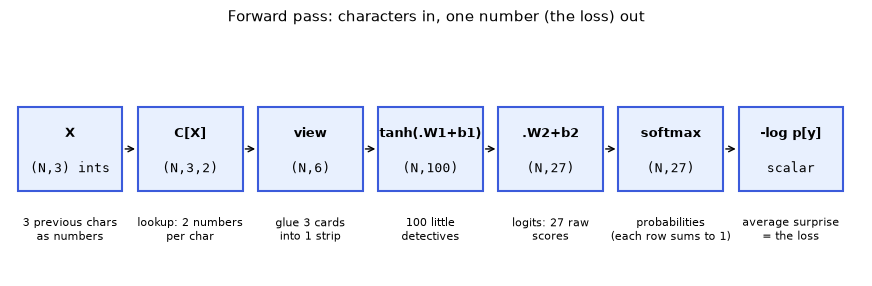

In [2]:
def draw_pipeline():
    fig, ax = plt.subplots(figsize=(11, 3.2))
    ax.axis("off"); ax.set_xlim(0, 11); ax.set_ylim(0, 3.2)
    steps = [("X", "(N,3) ints", "3 previous chars\nas numbers"),
             ("C[X]", "(N,3,2)", "lookup: 2 numbers\nper char"),
             ("view", "(N,6)", "glue 3 cards\ninto 1 strip"),
             ("tanh(.W1+b1)", "(N,100)", "100 little\ndetectives"),
             (".W2+b2", "(N,27)", "logits: 27 raw\nscores"),
             ("softmax", "(N,27)", "probabilities\n(each row sums to 1)"),
             ("-log p[y]", "scalar", "average surprise\n= the loss")]
    w, gap = 1.35, 0.2
    for i, (op, shape, desc) in enumerate(steps):
        x = 0.1 + i * (w + gap)
        ax.add_patch(plt.Rectangle((x, 1.1), w, 1.1, fc="#e8f0fe", ec="#3b5bdb", lw=1.5))
        ax.text(x + w/2, 1.85, op, ha="center", va="center", fontsize=9, fontweight="bold")
        ax.text(x + w/2, 1.4, shape, ha="center", va="center", fontsize=9, family="monospace")
        ax.text(x + w/2, 0.6, desc, ha="center", va="center", fontsize=8)
        if i < len(steps) - 1:
            ax.annotate("", xy=(x + w + gap, 1.65), xytext=(x + w, 1.65), arrowprops=dict(arrowstyle="->"))
    ax.set_title("Forward pass: characters in, one number (the loss) out", fontsize=11)
    plt.show()

draw_pipeline()

---
## 1. Data factory: names -> (context, target) pairs

### ELI5
Imagine reading a name through a **3-letter peephole**. You see three letters and must guess the next one. At the start of a name there are no letters yet, so the peephole shows `...` (dots = "nothing here"). After the last letter we guess a final `.` meaning "the name ends". Slide the peephole one step right, repeat. One name gives many practice questions.

### Math
For a name with $L$ letters, you get $L+1$ questions (the +1 is the end marker `.`). Over a list of names:
$$N=\sum_{w}\big(|w|+1\big)$$
Each question is a pair $(\mathbf{x},y)$ with $\mathbf{x}\in\{0..26\}^3$ (context, `block_size=3`) and $y\in\{0..26\}$ (the answer). Vocabulary size $V=27$ = 26 letters + `.`.

In [3]:
chars = sorted(set("".join(words)))
stoi = {s: i + 1 for i, s in enumerate(chars)}
stoi["."] = 0
itos = {i: s for s, i in stoi.items()}
V = len(stoi)
print("vocab size V =", V)

block_size = 3  # context length: how many previous chars we look at

def build_dataset(ws, verbose=False):
    X, Y = [], []
    for w in ws:
        if verbose: print(w)
        context = [0] * block_size
        for ch in w + ".":
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            if verbose: print("   ", "".join(itos[i] for i in context), "---->", itos[ix])
            context = context[1:] + [ix]   # drop oldest, append newest
    return torch.tensor(X), torch.tensor(Y)

_ = build_dataset(words[:2], verbose=True)
X, Y = build_dataset(words[:5])
print(X.shape, X.dtype, Y.shape, Y.dtype)

# verify the formula N = sum(len(w)+1)
assert len(X) == sum(len(w) + 1 for w in words[:5])
print("N =", len(X), " matches sum(len(w)+1) for the first 5 names")

vocab size V = 27
emma
    ... ----> e
    ..e ----> m
    .em ----> m
    emm ----> a
    mma ----> .
olivia
    ... ----> o
    ..o ----> l
    .ol ----> i
    oli ----> v
    liv ----> i
    ivi ----> a
    via ----> .
torch.Size([32, 3]) torch.int64 torch.Size([32]) torch.int64
N = 32  matches sum(len(w)+1) for the first 5 names


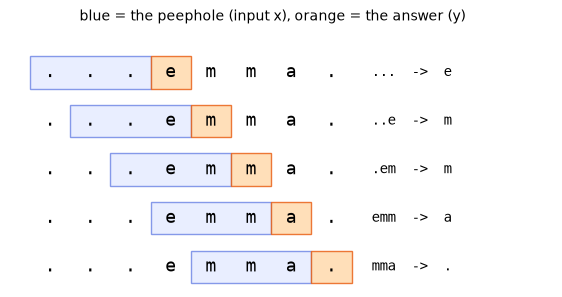

In [4]:
def show_window(word):
    padded = "." * block_size + word + "."
    n = len(word) + 1
    fig, axes = plt.subplots(n, 1, figsize=(7, 0.55 * n + 0.3))
    for t, ax in enumerate(axes):
        ax.axis("off"); ax.set_xlim(-0.5, len(padded) + 5); ax.set_ylim(0, 1)
        for i, ch in enumerate(padded):
            ax.text(i + 0.5, 0.5, ch, ha="center", va="center", family="monospace", fontsize=13)
        ax.add_patch(plt.Rectangle((t, 0.1), block_size, 0.8, fc="#dbe4ff", ec="#3b5bdb", alpha=0.6))
        ax.add_patch(plt.Rectangle((t + block_size, 0.1), 1, 0.8, fc="#ffd8a8", ec="#e8590c", alpha=0.8))
        ax.text(len(padded) + 0.5, 0.5, f"{padded[t:t+block_size]}  ->  {padded[t+block_size]}", va="center", family="monospace")
    plt.suptitle("blue = the peephole (input x), orange = the answer (y)", fontsize=10, y=1.02)
    plt.show()

show_window("emma")

> **Bug box (your cell 3):** you wrote `x.append(context)` / `y.append(ix)` (lowercase) while the lists are `X`, `Y` -> `NameError`. You fixed it in the next cell, but keep the habit of re-running top-to-bottom: lowercase/uppercase slips like this are exactly what a clean "Restart & Run All" catches.

> **Self-test:** In the 32 rows of your 5-name dataset, the input `[0,0,0]` appears 5 times. What are its 5 targets, and what does that imply about the *lowest loss any model could ever reach* on this tiny set? *(You will answer this with a number in section 8.)*

---
## 2. Embedding table `C`: giving every character a "home address"

### ELI5
Computers can't do maths on the letter `e`. So give each of the 27 characters an **ID card with 2 numbers** (an x, y address on a map). A table `C` with 27 rows holds all the cards. "Look up `e`" = "open locker number 5 and read the card". At the start the addresses are random; **training moves them** so that letters that behave alike (e.g. vowels) end up as neighbours.

Why 2 numbers? For *seeing* it on a plot. Real models use 10 to 12,288 (GPT-3).

### Math
$C\in\mathbb{R}^{27\times 2}$. Looking up character $i$ is the same as multiplying a **one-hot** row vector by $C$:
$$\mathbf{e}_i^{\top}\,C \;=\; C[i,:]$$
(the one-hot vector has a single 1 at position $i$, so the product just *selects* row $i$). Indexing is the fast way to do the same thing: no 27x2 multiply, and the gradient flows only into the selected rows.

For the whole dataset: `C[X]` has shape $(N,3,2)$: for each of the $N$ examples, 3 cards of 2 numbers.

**3B1B:**
- Embeddings as positions in a space, where similar meanings end up close: **GPT @ 12:27** ([link](https://www.youtube.com/watch?v=wjZofJX0v4M&t=747s)).
- "Matrix times a vector picks/combines columns": **LA3** ([link](https://www.youtube.com/watch?v=kYB8IZa5AuE)).

In [5]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((V, 2), generator=g)

print("C[5] ('e'):", C[5])
oh = F.one_hot(torch.tensor(5), num_classes=V)
print("one-hot dtype:", oh.dtype, "<- int64! must .float() before @ with a float matrix")
via_matmul = oh.float() @ C
print("one_hot @ C :", via_matmul)
assert torch.allclose(via_matmul, C[5])          # same thing as C[5]

print("\nC[[5,6,6]] (repeated ids are fine):\n", C[[5, 6, 6]])

emb = C[X]
print("\nC[X].shape =", emb.shape, " = (N examples, 3 chars, 2 numbers)")
assert torch.equal(emb[13, 2], C[X[13, 2]])      # row 13, third char -> the card of that char id
print("emb[13,2] == C[X[13,2]] ==", emb[13, 2], "-> char", itos[X[13, 2].item()])

C[5] ('e'): tensor([-0.4713,  0.7868])
one-hot dtype: torch.int64 <- int64! must .float() before @ with a float matrix
one_hot @ C : tensor([-0.4713,  0.7868])

C[[5,6,6]] (repeated ids are fine):
 tensor([[-0.4713,  0.7868],
        [-0.3284, -0.4330],
        [-0.3284, -0.4330]])

C[X].shape = torch.Size([32, 3, 2])  = (N examples, 3 chars, 2 numbers)
emb[13,2] == C[X[13,2]] == tensor([-0.0274, -1.1008]) -> char a


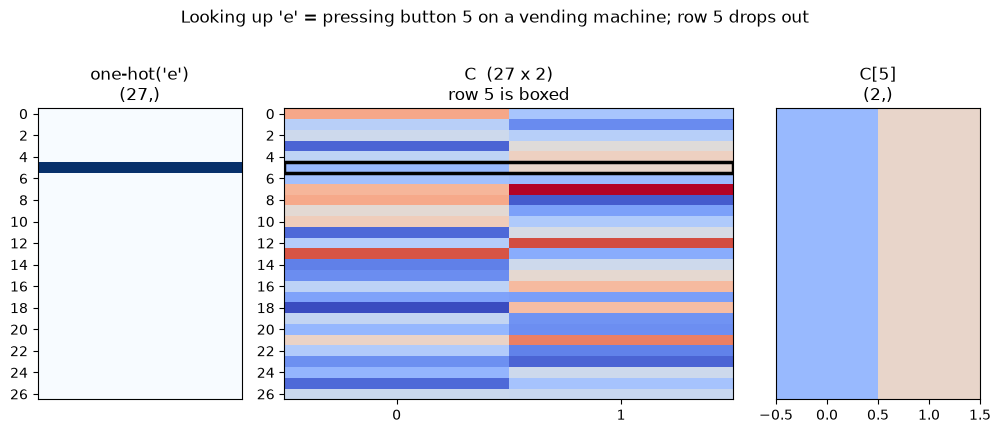

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(10, 4.2), gridspec_kw={"width_ratios": [1, 2.2, 1]})
axs[0].imshow(oh.float().view(-1, 1), cmap="Blues", aspect="auto"); axs[0].set_title("one-hot('e')\n(27,)"); axs[0].set_yticks(range(0, V, 2)); axs[0].grid(False); axs[0].set_xticks([])
axs[1].imshow(C.detach(), cmap="coolwarm", aspect="auto"); axs[1].set_title("C  (27 x 2)\nrow 5 is boxed"); axs[1].grid(False)
axs[1].add_patch(plt.Rectangle((-0.5, 4.5), 2, 1, fill=False, ec="k", lw=2.5)); axs[1].set_xticks([0, 1]); axs[1].set_yticks(range(0, V, 2))
axs[2].imshow(C[5].detach().view(1, -1), cmap="coolwarm", aspect="auto", vmin=C.min(), vmax=C.max()); axs[2].set_title("C[5]\n(2,)"); axs[2].grid(False); axs[2].set_yticks([])
plt.suptitle("Looking up 'e' = pressing button 5 on a vending machine; row 5 drops out", y=1.02); plt.tight_layout(); plt.show()

> **Bug box:** your cell 12 shows `F.one_hot(...)` is `int64`. Multiplying int64 by a float matrix raises an error, so you correctly used `.float()` in cell 13. Rule: `one_hot` always returns integers.

> **Self-test:** `C[X]` and `F.one_hot(X, 27).float() @ C` give the same numbers. Why does PyTorch practitioners' code never use the second form for real training?
<details><summary>Answer</summary>
It builds an $(N,3,27)$ mostly-zero tensor and does $27\times$ more multiplications just to copy rows. Indexing copies exactly the rows needed, and backprop only updates those rows.
</details>

---
## 3. Reshape: `(N,3,2)` -> `(N,6)` with `view`

### ELI5
Each example has **three 2-number cards**. The next layer wants **one strip of 6 numbers**. Two ways to make the strip:
- **`torch.cat`**: photocopy the cards and paste them side by side (new memory, slow).
- **`.view`**: don't touch the numbers at all, just *relabel* how you read them. Computer memory is one long tape; "shape" is only the reading instruction. Free.

### Math
Shapes are views on a flat tape of $N\cdot3\cdot2$ numbers in row-major order. `view(-1, 6)` means "6 columns, you work out the rows": $\;-1 = \dfrac{\text{total}}{6}=N$.



In [7]:
a = torch.arange(18)
print("a            :", a.shape)
print("a.view(3,3,2):", a.view(3, 3, 2).shape)
print(a.view(3, 3, 2))

same_tape = a.view(3, 3, 2).untyped_storage().data_ptr() == a.untyped_storage().data_ptr()
print("\nview shares the SAME memory as the original:", same_tape)

cat_version = torch.cat(torch.unbind(emb, 1), 1)      # (N,6) by copying
view_version = emb.view(-1, 6)                          # (N,6) by relabelling
print("cat   -> new memory?", cat_version.untyped_storage().data_ptr() != emb.untyped_storage().data_ptr())
print("view  -> new memory?", view_version.untyped_storage().data_ptr() != emb.untyped_storage().data_ptr())
print("same numbers?", torch.equal(cat_version, view_version), view_version.shape)

# proof that it's one tape: change through the view, original changes
b = torch.arange(6); v = b.view(2, 3); v[0, 0] = 99
print("\nwrite through the view ->", b, "(original changed too)")

a            : torch.Size([18])
a.view(3,3,2): torch.Size([3, 3, 2])
tensor([[[ 0,  1],
         [ 2,  3],
         [ 4,  5]],

        [[ 6,  7],
         [ 8,  9],
         [10, 11]],

        [[12, 13],
         [14, 15],
         [16, 17]]])

view shares the SAME memory as the original: True
cat   -> new memory? True
view  -> new memory? False
same numbers? True torch.Size([32, 6])

write through the view -> tensor([99,  1,  2,  3,  4,  5]) (original changed too)


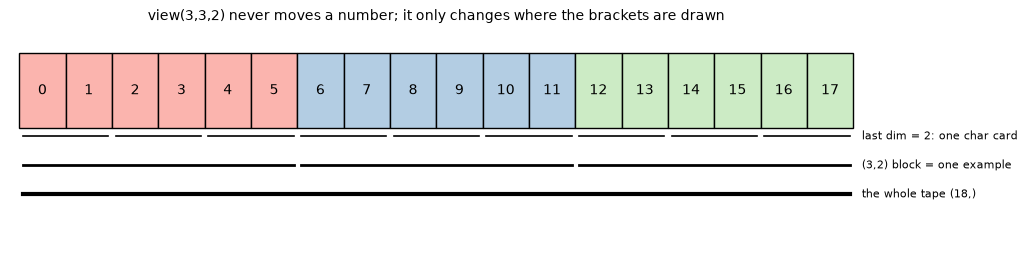

In [8]:
fig, ax = plt.subplots(figsize=(11, 2.8)); ax.axis("off"); ax.set_xlim(-0.2, 18.2); ax.set_ylim(0, 2.6)
for i in range(18):
    ax.add_patch(plt.Rectangle((i, 1.4), 1, 0.9, fc=plt.cm.Pastel1(i // 6), ec="k"))
    ax.text(i + 0.5, 1.85, str(i), ha="center", va="center")
for k in range(9):
    ax.plot([2*k + 0.08, 2*k + 1.92], [1.3, 1.3], "k", lw=1.2)
ax.text(18.1, 1.3, " last dim = 2: one char card", va="center", fontsize=8, ha="left")
for k in range(3):
    ax.plot([6*k + 0.08, 6*k + 5.92], [0.95, 0.95], "k", lw=2)
ax.text(18.1, 0.95, " (3,2) block = one example", va="center", fontsize=8, ha="left")
ax.plot([0.08, 17.92], [0.6, 0.6], "k", lw=3); ax.text(18.1, 0.6, " the whole tape (18,)", va="center", fontsize=8, ha="left")
ax.set_title("view(3,3,2) never moves a number; it only changes where the brackets are drawn", fontsize=10)
plt.show()

> **Bug box (your cell 23):** `emb @ w1 + b` fails twice: `emb` is `(32,3,2)` but `w1` is `(6,100)` (inner dims don't match), and `b` is undefined (it is `b1`). You fixed it correctly with `emb.view(-1,6) @ w1 + b1`.
> **Also:** `a.storage()` (your cell 32) is deprecated; use `a.untyped_storage()`.
> **Caveat on `view`:** it only works if the tensor is contiguous in memory. `reshape` is the safe version (view if possible, else copy).

> **Self-test:** If you change `view(-1, 6)` to `view(6, -1)`, the code runs without error. Why is that *worse* than an error?
<details><summary>Answer</summary>
It silently reads the tape with the wrong brackets: "cards" from different examples get mixed into one row. Wrong shapes that still multiply are the most dangerous bugs, so always assert shapes.
</details>

---
## 4. Hidden layer: 100 detectives + a loudness limiter (`tanh`)

### ELI5
Hand the 6-number strip to **100 detectives**. Each detective has her own list of 6 "how much do I care about this number" weights, adds a personal mood (bias), and shouts out one number. Then a **limiter** (`tanh`) squashes every shout into the range $-1\ldots+1$, so nobody can scream arbitrarily loud. Without the limiter, stacking layers would collapse into one big multiplication (a straight line); the squash is what lets the network draw curves.

### Math
$$\mathbf{h}=\tanh\!\big(\mathbf{x}\,W_1+\mathbf{b}_1\big),\qquad \mathbf{x}\in\mathbb{R}^{6},\;W_1\in\mathbb{R}^{6\times100},\;\mathbf{b}_1\in\mathbb{R}^{100}$$
For a batch: $X_{\text{flat}}\in\mathbb{R}^{N\times6}$, so $X_{\text{flat}}W_1\in\mathbb{R}^{N\times100}$. One entry:
$$h_{n,j}=\tanh\!\Big(\sum_{k=1}^{6}x_{n,k}\,W_{1,kj}+b_{1,j}\Big)$$
$$\frac{d}{du}\tanh u = 1-\tanh^2 u\;\;\Rightarrow\;\;\text{when }|\tanh u|\approx1,\text{ the slope}\approx 0$$
That last line is **saturation**: a detective who is shouting at the ceiling can't be corrected, because her gradient is ~0.

**Broadcasting:** `(N,100) + (100,)`. Shapes are aligned from the **right**; a missing/size-1 dim is stretched. `(100,)` is treated as `(1,100)` and copied down all $N$ rows. (Your comment in cell 45 said `(32,100) + (1,1000)`; the bias is `(100,)`, not 1000.)

**3B1B:**
- Weights, biases, "squishing" activation, layers: **NN1** ([link](https://www.youtube.com/watch?v=aircAruvnKk)).
- Why `x @ W` is a transformation of space and chained matrices compose: **LA3** ([link](https://www.youtube.com/watch?v=kYB8IZa5AuE)), **LA4** ([link](https://www.youtube.com/watch?v=XkY2DOUCWMU)).

In [9]:
g = torch.Generator().manual_seed(2147483647)
C  = torch.randn((V, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)

x   = C[X].view(-1, 6)
pre = x @ W1 + b1               # (N,100) before the limiter
h   = torch.tanh(pre)           # (N,100)
print("x", tuple(x.shape), " pre", tuple(pre.shape), " h", tuple(h.shape))

# 1) verify ONE entry by hand: example n=3, detective j=7
n, j = 3, 7
by_hand = sum(x[n, k] * W1[k, j] for k in range(6)) + b1[j]
print("by hand:", by_hand.item(), " matrix:", pre[n, j].item())
assert torch.allclose(by_hand, pre[n, j], atol=1e-5)

# 2) verify broadcasting: bias copied to every row
assert torch.allclose(pre - x @ W1, b1.expand_as(pre), atol=1e-5)
print("broadcast check passed: pre - xW1 == b1 repeated on all rows")

# 3) parameter count of this layer
print("W1+b1 parameters:", W1.numel() + b1.numel(), "= 6*100 + 100")

x (32, 6)  pre (32, 100)  h (32, 100)
by hand: -0.36156195402145386  matrix: -0.36156201362609863
broadcast check passed: pre - xW1 == b1 repeated on all rows
W1+b1 parameters: 700 = 6*100 + 100


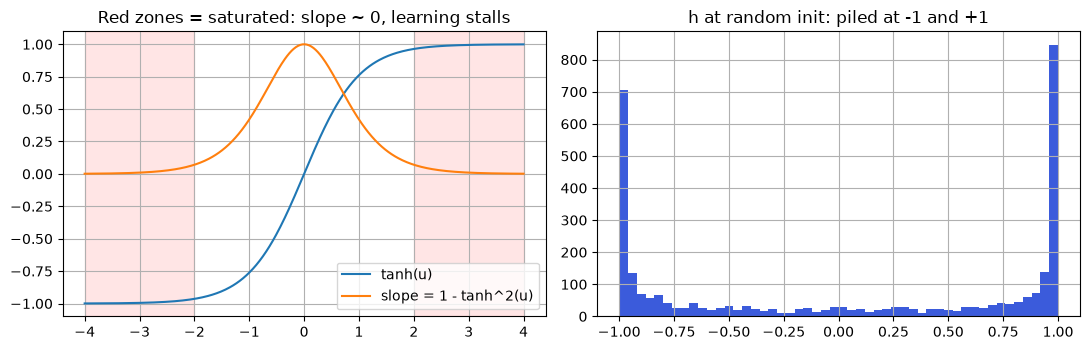

Fraction of detectives with |h|>0.99 at init: 32.7%  (their gradient is ~0)
pre-activation std: 2.8389813899993896  <- expected about sqrt(6+1)=2.65 (6 inputs ~N(0,1) times N(0,1) weights, plus a bias)


In [10]:
u = torch.linspace(-4, 4, 400)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].plot(u, torch.tanh(u), label="tanh(u)"); axs[0].plot(u, 1 - torch.tanh(u)**2, label="slope = 1 - tanh^2(u)")
axs[0].axvspan(-4, -2, alpha=0.1, color="r"); axs[0].axvspan(2, 4, alpha=0.1, color="r")
axs[0].set_title("Red zones = saturated: slope ~ 0, learning stalls"); axs[0].legend()
axs[1].hist(h.flatten().detach(), bins=50, color="#3b5bdb"); axs[1].set_title("h at random init: piled at -1 and +1")
plt.tight_layout(); plt.show()

sat = (h.abs() > 0.99).float().mean().item()
print(f"Fraction of detectives with |h|>0.99 at init: {sat:.1%}  (their gradient is ~0)")
print("pre-activation std:", pre.std().item(), " <- expected about sqrt(6+1)=2.65 (6 inputs ~N(0,1) times N(0,1) weights, plus a bias)")

> **Why this matters later:** at random init, many detectives start saturated, and the output layer (next section) makes confident guesses. That is exactly why your first loss was ~17.8 instead of ~3.3.

> **Self-test:** Two layers with *no* `tanh`: $\mathbf{y}=(\mathbf{x}W_1)W_2$. Show it equals a single layer.
<details><summary>Answer</summary>
Matrix multiplication is associative: $(\mathbf{x}W_1)W_2=\mathbf{x}(W_1W_2)$, and $W_1W_2$ is just one matrix. That is LA4's "composition of two transformations is one transformation". The non-linearity is what stops this collapse.
</details>

---
## 5. Output layer: logits -> softmax -> probabilities

### ELI5
For each of the 27 possible next characters, a **judge** gives a raw score (a **logit**: any number, negative allowed, "how much do I like this letter"). Raw scores aren't percentages, so we convert them into a **pie chart** that adds to 100%:
1. `exp` each score (makes everything positive, and *amplifies* the leader: a score 3 higher gets $e^3\approx20\times$ the share).
2. Divide by the total (so shares add to 1).

### Math
$$z=hW_2+b_2\in\mathbb{R}^{27},\qquad p_j=\operatorname{softmax}(z)_j=\frac{e^{z_j}}{\sum_{k=1}^{27}e^{z_k}}$$
Temperature $T$ (used when sampling): $\;p_j(T)=\dfrac{e^{z_j/T}}{\sum_k e^{z_k/T}}$. Small $T$ -> sharp/greedy; large $T$ -> flat/random.

**3B1B:**
- Logits, softmax, **temperature**: **GPT @ 22:22** ([link](https://www.youtube.com/watch?v=wjZofJX0v4M&t=1342s)); unembedding (last vector -> 27 or 50,257 scores): **GPT @ 20:22** ([link](https://www.youtube.com/watch?v=wjZofJX0v4M&t=1222s)).
- Why `exp` is the natural choice (it is its own slope): **CALC5** ([link](https://www.youtube.com/watch?v=m2MIpDrF7Es)).

In [11]:
W2 = torch.randn((100, V), generator=g)
b2 = torch.randn(V, generator=g)
logits = h @ W2 + b2
print("logits", tuple(logits.shape), "  parameters in W2+b2:", W2.numel() + b2.numel())

counts = logits.exp()
prob = counts / counts.sum(1, keepdim=True)         # keepdim=True is NOT optional, see bug box
assert torch.allclose(prob, F.softmax(logits, dim=1))
print("each row sums to 1:", torch.allclose(prob.sum(1), torch.ones(len(prob))))
print("logit std at init:", logits.std().item(), " <- large: the judges are shouting, not whispering")

logits (32, 27)   parameters in W2+b2: 2727
each row sums to 1: True
logit std at init: 8.589914321899414  <- large: the judges are shouting, not whispering


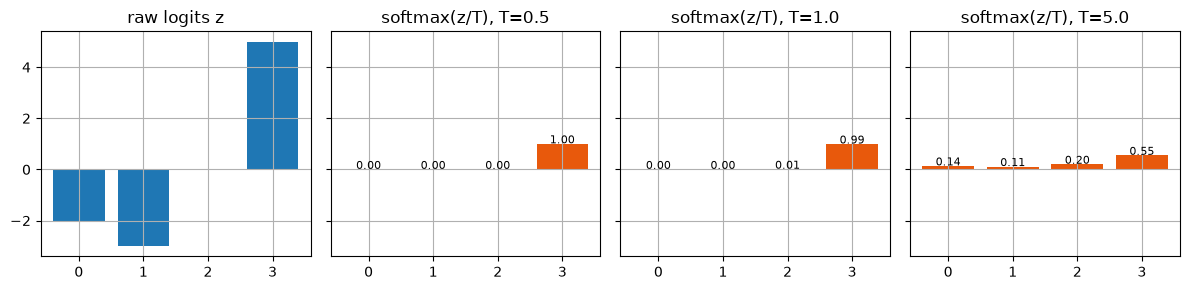

T=1 probs: tensor([9.0466e-04, 3.3281e-04, 6.6846e-03, 9.9208e-01])


In [12]:
z = torch.tensor([-2., -3., 0., 5.])
fig, axs = plt.subplots(1, 4, figsize=(12, 3), sharey=True)
axs[0].bar(range(4), z); axs[0].set_title("raw logits z")
for ax, T in zip(axs[1:], [0.5, 1.0, 5.0]):
    p = F.softmax(z / T, dim=0)
    ax.bar(range(4), p, color="#e8590c"); ax.set_title(f"softmax(z/T), T={T}")
    for i, v in enumerate(p): ax.text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=8)
plt.tight_layout(); plt.show()
print("T=1 probs:", F.softmax(z, 0))

> **Bug box (silent!):** `counts.sum(1, keepdims=True)` keeps the shape `(N,1)` so each row is divided by *its own* total. Without it the sum has shape `(N,)` and Python tries to line it up against the **last** dimension. Demo below: it only errors when shapes don't happen to match, and **silently gives wrong numbers** when they do.

In [13]:
m = torch.tensor([[1., 2.], [3., 4.]])
right = m / m.sum(1, keepdim=True)     # divide each ROW by its own total
wrong = m / m.sum(1)                   # (2,) broadcasts across columns -> divides by the wrong things
print("right:\n", right, "\n rows sum to:", right.sum(1))
print("wrong:\n", wrong, "\n rows sum to:", wrong.sum(1), "<- not 1, and no error was raised")

right:
 tensor([[0.3333, 0.6667],
        [0.4286, 0.5714]]) 
 rows sum to: tensor([1., 1.])
wrong:
 tensor([[0.3333, 0.2857],
        [1.0000, 0.5714]]) 
 rows sum to: tensor([0.6190, 1.5714]) <- not 1, and no error was raised


> **Self-test:** Add 100 to every logit. Do the probabilities change? Why or why not? *(Keep your answer; it is the key to section 7.)*

---
## 6. Loss: "how surprised was the model by the truth?"

### ELI5
Before showing the true letter, the model gave a % to every letter. Look at the % it gave to the **true** one:
- gave it 90% -> "yeah, expected", tiny surprise.
- gave it 0.001% -> "WHAT?!", huge surprise.
The loss is the **average surprise** over all examples. Training = making the model less surprised by reality.

### Math
Surprise of an event with probability $p$ is $-\log p$ (0 when $p=1$; $\to\infty$ as $p\to0$). With the model's probabilities $p_{n,j}$ and true labels $y_n$:
$$\boxed{\;\mathcal{L}=-\frac1N\sum_{n=1}^{N}\log p_{n,\,y_n}\;}$$
This is the **negative log-likelihood** = **cross-entropy**. Sanity baseline: a model that says $1/27$ for everything has
$$\mathcal{L}_{\text{uniform}}=-\log\tfrac1{27}=\ln 27\approx3.296$$
Anything above 3.296 is *worse than not knowing anything*.

**Code meaning of `prob[torch.arange(N), Y]`:** "for row $n$, take column $Y_n$" (fancy indexing pairs row-indices with column-indices) -> a vector of length $N$ holding the probability given to the right answer.

**3B1B:** surprise/information in bits, $-\log_2 p$: **INFO @ 8:04 onward** ([link](https://www.youtube.com/watch?v=v68zYyaEmEA&t=484s)). PyTorch uses $\ln$ (nats) instead of $\log_2$ (bits); same idea, different unit.

In [14]:
N = len(Y)
p_correct = prob[torch.arange(N), Y]
loss_manual = -p_correct.log().mean()
loss_ce = F.cross_entropy(logits, Y)
print("manual NLL      :", loss_manual.item())
print("F.cross_entropy :", loss_ce.item())
assert torch.allclose(loss_manual, loss_ce)
print("uniform-guess baseline ln(27) =", math.log(27))
print("probability given to the true letter, first 6 rows:", p_correct[:6])

manual NLL      : 17.769712448120117
F.cross_entropy : 17.76971435546875
uniform-guess baseline ln(27) = 3.295836866004329
probability given to the true letter, first 6 rows: tensor([1.5213e-14, 1.2830e-12, 1.9647e-08, 3.1758e-10, 5.6763e-12, 1.0823e-10])


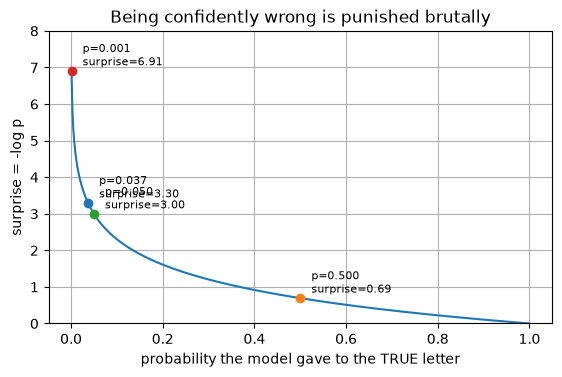

In [15]:
p = torch.linspace(0.001, 1, 500)
plt.plot(p, -p.log()); plt.ylim(0, 8)
for pv in [1/27, 0.5, 0.05, 0.001]:
    plt.scatter([pv], [-math.log(pv)], zorder=5); plt.annotate(f"p={pv:.3f}\nsurprise={-math.log(pv):.2f}", (pv, -math.log(pv)), textcoords="offset points", xytext=(8, 4), fontsize=8)
plt.xlabel("probability the model gave to the TRUE letter"); plt.ylabel("surprise = -log p"); plt.title("Being confidently wrong is punished brutally")
plt.show()

### Why was your first loss 17.77 when "knowing nothing" gives 3.30?
Intuition: the random weights make the judges **shout** (logit std ~9), so the model typically puts 90%+ on one random letter (median 96% on your 32 rows) and almost nothing on the true one. Confident and wrong = huge surprise.
Verify: shrink the output layer so the logits are near zero and the loss should snap to $\approx\ln 27$.

In [16]:
logits_small = h @ (W2 * 0.01) + b2 * 0
print("loss with tiny output weights:", F.cross_entropy(logits_small, Y).item(), " vs ln27 =", math.log(27))
print("loss with your randn weights :", loss_ce.item())

loss with tiny output weights: 3.296867609024048  vs ln27 = 3.295836866004329
loss with your randn weights : 17.76971435546875


> **Take-away:** a good initial loss is ~$\ln V$. If you see 17, the *init* is broken, not the data. (Scaling `W2` by 0.01 and zeroing `b2` is the standard fix; Karpathy's next lecture builds on it.)

> **Why `F.cross_entropy` instead of your manual 4 lines:** (1) one fused, memory-efficient kernel, (2) numerically stable (next section), (3) a simpler, cleaner backward pass.

> **Self-test:** A model assigns the true letter probability 0.5 on every example. What's the loss, and how many bits of surprise is that?

<details><summary>Answer</summary>
$-\ln 0.5=0.693$ nats $=1$ bit (one fair coin flip of surprise).
</details>

---
## 7. Numerical stability: why `exp` can blow up and the "subtract the max" trick

### ELI5
`exp` makes numbers explode. A computer's number slot has a ceiling (like a scoreboard with limited digits). If a judge's score is 100, $e^{100}$ doesn't fit and the scoreboard shows **inf**; `inf/inf` = **nan**. Fix: before exponentiating, **subtract the highest score from everyone**. Pie shares depend only on *differences* between scores, so nothing real changes, but now the biggest number is $e^0=1$ and nothing overflows.

### Math
For any constant $c$:
$$\frac{e^{z_j-c}}{\sum_k e^{z_k-c}}=\frac{e^{-c}e^{z_j}}{e^{-c}\sum_k e^{z_k}}=\frac{e^{z_j}}{\sum_k e^{z_k}}$$
Pick $c=\max_k z_k$. Float32 overflows when $z>\ln(\text{float32 max})\approx 88.72$.
Log-softmax directly (this is what `F.cross_entropy` does internally):
$$\log p_y=z_y-\underbrace{\log\sum_k e^{z_k}}_{\text{logsumexp}}$$

In [17]:
print("float32 overflow threshold ln(max):", math.log(torch.finfo(torch.float32).max))
print("exp(88.) =", torch.tensor(88.).exp().item(), "  exp(89.) =", torch.tensor(89.).exp().item())

z = torch.tensor([-100., -3., 0., 100.])
naive = z.exp() / z.exp().sum()
print("\nnaive softmax          :", naive, "<- nan")
shifted = (z - z.max()).exp()
stable = shifted / shifted.sum()
print("subtract-max softmax   :", stable)
print("F.softmax              :", F.softmax(z, 0))
assert torch.allclose(stable, F.softmax(z, 0))

# the section-5 self-test: adding a constant to all logits changes nothing
z2 = torch.tensor([-2., -3., 0., 5.])
assert torch.allclose(F.softmax(z2, 0), F.softmax(z2 + 100, 0))
print("\nsoftmax(z) == softmax(z+100): True  (only differences matter)")

# cross_entropy survives huge logits; the manual version does not
bad = torch.tensor([[-100., -3., 0., 100.]]); y = torch.tensor([3])
manual = -(bad.exp() / bad.exp().sum(1, keepdim=True))[0, 3].log()
print("manual loss:", manual.item(), " F.cross_entropy:", F.cross_entropy(bad, y).item())
print("logsumexp identity holds:", torch.allclose(-(bad[0, 3] - torch.logsumexp(bad[0], 0)), F.cross_entropy(bad, y)))

float32 overflow threshold ln(max): 88.72283905206835
exp(88.) = 1.6516362661361307e+38   exp(89.) = inf

naive softmax          : tensor([0., 0., 0., nan]) <- nan
subtract-max softmax   : tensor([0.0000e+00, 1.4013e-45, 3.7835e-44, 1.0000e+00])
F.softmax              : tensor([0.0000e+00, 1.4013e-45, 3.7835e-44, 1.0000e+00])

softmax(z) == softmax(z+100): True  (only differences matter)
manual loss: nan  F.cross_entropy: 0.0
logsumexp identity holds: True


> **Bug box:** in your cell 64 you saw `counts = [3.78e-44, 4.98e-02, 1.0, inf]` -> `nan`. That is exactly this overflow. Your cell 66 (subtract 90) fixed it. You never need to do it by hand: `F.cross_entropy` / `F.softmax` already do.

> **Self-test:** Why does subtracting the max (instead of, say, the mean) guarantee no overflow?
<details><summary>Answer</summary>
After subtracting the max, every exponent is $\le0$, so every $e^{\cdot}\le1$; the sum is between 1 and $V$. No overflow is possible. (Underflow of the small ones to 0 is harmless.)
</details>

---
## 8. Learning: gradient descent + backprop

### ELI5
You are **blindfolded on a hilly field**; height = loss; you want the valley. You can't see, but you can feel the **slope** under your feet. So: feel the slope, take a step **downhill**, repeat. The **learning rate** is your stride length: tiny strides take forever, giant strides overshoot the valley and launch you up the other side.

The field has 3,481 dimensions (one per parameter). **Backpropagation** is the bookkeeping trick that gets the slope for *all 3,481 knobs at once*: it passes **blame backwards** from the loss. Each knob learns "if I wiggle up a tiny bit, how much does the loss change?"

### Math
$$\theta\;\leftarrow\;\theta-\eta\,\nabla_\theta\mathcal{L}$$
Note the **minus**: we move *against* the gradient. Backprop = the chain rule applied layer by layer:
$$\frac{\partial\mathcal{L}}{\partial W_1}=\frac{\partial\mathcal{L}}{\partial z}\cdot\frac{\partial z}{\partial h}\cdot\frac{\partial h}{\partial \text{pre}}\cdot\frac{\partial\text{pre}}{\partial W_1}$$
The first factor, for softmax + cross-entropy, simplifies to something beautiful:
$$\boxed{\;\frac{\partial\mathcal{L}}{\partial z_{n,j}}=\frac{1}{N}\big(p_{n,j}-\mathbb{1}[j=y_n]\big)\;}$$
"push down each wrong letter by the probability you wasted on it; push up the right letter by what's missing."

**3B1B:** gradient descent and cost surfaces: **NN2** ([link](https://www.youtube.com/watch?v=IHZwWFHWa-w)). Backprop intuition ("blame passing"): **NN3** ([link](https://www.youtube.com/watch?v=Ilg3gGewQ5U)). The chain-rule maths: **NN4** ([link](https://www.youtube.com/watch?v=tIeHLnjs5U8)) and **CALC4** ([link](https://www.youtube.com/watch?v=YG15m2VwSjA)).

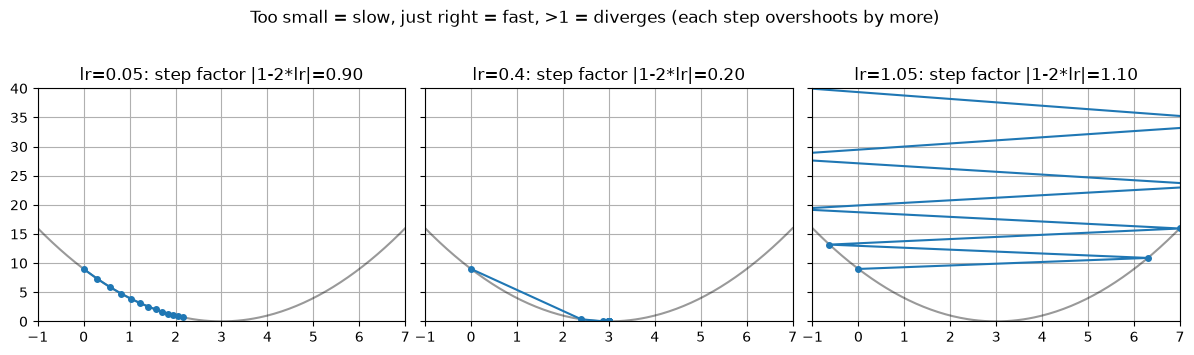

In [18]:
# 1D hill to build the intuition: L(w) = (w-3)^2, slope = 2(w-3)
def descend(eta, w=0.0, steps=12):
    path = [w]
    for _ in range(steps):
        w = w - eta * 2 * (w - 3)
        path.append(w)
    return path

ws = torch.linspace(-1, 7, 200)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, eta in zip(axs, [0.05, 0.4, 1.05]):
    path = descend(eta)
    ax.plot(ws, (ws - 3)**2, "k", alpha=0.4)
    ax.plot(path, [(w - 3)**2 for w in path], "o-", ms=4)
    ax.set_title(f"lr={eta}: step factor |1-2*lr|={abs(1-2*eta):.2f}"); ax.set_ylim(0, 40); ax.set_xlim(-1, 7)
plt.suptitle("Too small = slow, just right = fast, >1 = diverges (each step overshoots by more)", y=1.03)
plt.tight_layout(); plt.show()

In [19]:
def init_params(emb_dim=2, hidden=100, seed=2147483647):
    g = torch.Generator().manual_seed(seed)
    C  = torch.randn((V, emb_dim), generator=g)
    W1 = torch.randn((block_size * emb_dim, hidden), generator=g)
    b1 = torch.randn(hidden, generator=g)
    W2 = torch.randn((hidden, V), generator=g)
    b2 = torch.randn(V, generator=g)
    ps = [C, W1, b1, W2, b2]
    for p in ps: p.requires_grad_(True)
    return ps

def forward(ps, Xb):
    C, W1, b1, W2, b2 = ps
    emb = C[Xb]
    h = torch.tanh(emb.view(emb.shape[0], -1) @ W1 + b1)
    return h @ W2 + b2

ps = init_params()
print("total parameters:", sum(p.numel() for p in ps), "(= 27*2 + 6*100+100 + 100*27+27 = 54+700+2727)")

# --- verify the boxed formula against autograd ---
logits = forward(ps, X)
logits.retain_grad()
loss = F.cross_entropy(logits, Y)
loss.backward()
expected = (F.softmax(logits.detach(), 1) - F.one_hot(Y, V)) / len(Y)
print("max |autograd - (p - onehot)/N| =", (logits.grad - expected).abs().max().item())
assert torch.allclose(logits.grad, expected, atol=1e-6)
print("loss at init:", loss.item(), "(your notebook: 17.7697)")

total parameters: 3481 (= 27*2 + 6*100+100 + 100*27+27 = 54+700+2727)
max |autograd - (p - onehot)/N| = 1.862645149230957e-09
loss at init: 17.76971435546875 (your notebook: 17.7697)


### The sign bug that wrecked your training
Your update was `p.data += 0.1 * p.grad`. The gradient points **uphill**. `+=` walks uphill: that's gradient **ascent**. Your own outputs show the evidence: loss `17.77 -> 87.98` after 10 steps, then `203.6`, then `11,468.7`. Loss only goes *up* when you maximise it. Reproduce both:

YOUR code (+=), 10 steps: [17.8, 88.0] -> loss grows. (yours printed 87.98)
Theoretical floor = 5*ln(5)/32 = 0.2515  (the 5 rows with input '...' can at best get p=1/5 each)


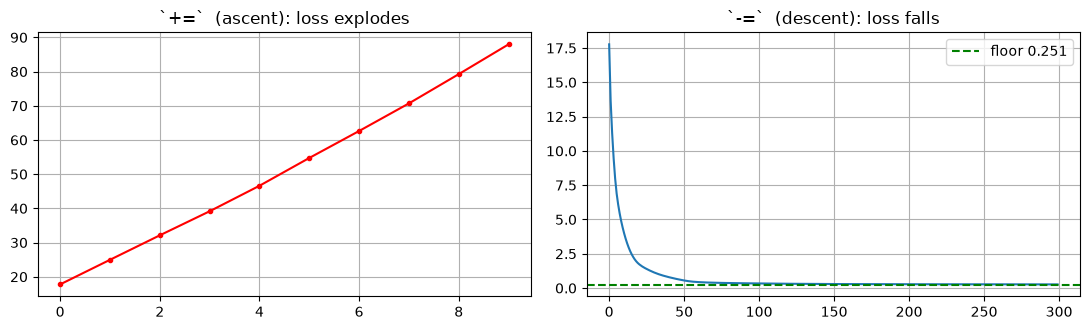

final descent loss after 300 steps: 0.26795491576194763


In [20]:
def run(sign, steps, lr=0.1, Xd=X, Yd=Y):
    ps = init_params()
    hist = []
    for _ in range(steps):
        loss = F.cross_entropy(forward(ps, Xd), Yd)
        for p in ps: p.grad = None
        loss.backward()
        with torch.no_grad():
            for p in ps:
                p += sign * lr * p.grad      # sign=+1 is YOUR code (ascent); sign=-1 is correct
        hist.append(loss.item())
    return hist

ascent  = run(+1, 10)
descent = run(-1, 300)
print("YOUR code (+=), 10 steps:", [round(v, 1) for v in ascent[:1] + ascent[-1:]], "-> loss grows. (yours printed 87.98)")

# lowest possible loss on this 32-example set: the input '...' has 5 different answers
floor = 5 * math.log(5) / 32
print(f"Theoretical floor = 5*ln(5)/32 = {floor:.4f}  (the 5 rows with input '...' can at best get p=1/5 each)")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].plot(ascent, "r.-"); axs[0].set_title("`+=`  (ascent): loss explodes")
axs[1].plot(descent); axs[1].axhline(floor, color="g", ls="--", label=f"floor {floor:.3f}"); axs[1].set_title("`-=`  (descent): loss falls"); axs[1].legend()
plt.tight_layout(); plt.show()
print("final descent loss after 300 steps:", descent[-1])

**Answer to the section-1 self-test:** the 5 names start with `e, o, a, i, s`, all with the same input `...`. No function of the input can tell them apart, so the best it can do is 1/5 each: $-\ln\frac15=1.609$ on those 5 rows, 0 elsewhere -> $5\times1.609/32=0.2515$. The loss can approach that floor but **never 0**. If your loss goes below it on this set, something is leaking.

> **Idiom upgrade:** `p.data += ...` bypasses autograd silently. Prefer `with torch.no_grad(): p -= lr * p.grad`.
> **Why overfit 32 examples on purpose?** It's a sanity check: if a net can't memorise 32 examples, the pipeline is broken. It says nothing about quality.

> **Self-test:** The loss at some parameter value has gradient $+4$ and $\eta=0.1$. In which direction and by how much does the parameter move?
<details><summary>Answer</summary>
$\theta\leftarrow\theta-0.1\cdot4=\theta-0.4$: it decreases by 0.4. Positive gradient means the loss rises when $\theta$ rises, so we go the other way.
</details>

---
## 9. Train / dev / test split

### ELI5
Three exams:
- **Train** = practice questions you study from (80%).
- **Dev / validation** = a mock exam to choose settings (10%). You may peek at this repeatedly.
- **Test** = the real final exam (10%). Look **once**, at the very end, otherwise you start tuning to it and the score lies.

A student who memorises answers to the practice questions can ace them and fail a new exam. That's **overfitting**.

### Math
Generalisation gap $=\mathcal{L}_{\text{dev}}-\mathcal{L}_{\text{train}}$. Large positive gap = memorising. Both high = **underfitting** (model too small / trained too little).



In [21]:
random.seed(42)
shuffled = words[:]                   # copy: don't mutate the global list (your cell 75 shuffled `words` in place)
random.shuffle(shuffled)
n1, n2 = int(0.8 * len(shuffled)), int(0.9 * len(shuffled))

Xtr,  Ytr  = build_dataset(shuffled[:n1])
Xdev, Ydev = build_dataset(shuffled[n1:n2])
Xte,  Yte  = build_dataset(shuffled[n2:])
for name, A in [("train", Xtr), ("dev", Xdev), ("test", Xte)]:
    print(f"{name:5s}: {A.shape[0]:>7,} examples")
print("total:", Xtr.shape[0] + Xdev.shape[0] + Xte.shape[0], "(your notebook: 182625 / 22655 / 22866 -> 228,146)")

train: 182,625 examples
dev  :  22,655 examples
test :  22,866 examples
total: 228146 (your notebook: 182625 / 22655 / 22866 -> 228,146)


> **Why split by *names*, not by rows:** we shuffle the list of names *then* build examples, so no single name leaks across splits (e.g. `.em`->`m` in train and `emm`->`a` in dev would share the same word).

> **Self-test:** You try 50 hyper-parameter settings and report the best *dev* loss as your final result. What's wrong?
<details><summary>Answer</summary>
You picked the winner by looking at dev 50 times, so dev is now partly "trained on" by your choices and is optimistic. Report the *test* loss of the chosen model, evaluated once.
</details>

---
## 10. Mini-batches: poll 32 voters, not the whole country

### ELI5
Computing the exact slope needs all 182,625 examples every single step: slow. Instead grab **32 random examples**, compute the slope from just those, step. The direction is a bit noisy (a drunk walking downhill), but you take *thousands* of cheap steps instead of a handful of expensive ones. Noisy-and-fast beats exact-and-slow.

### Math
$$\nabla\mathcal{L}\;\approx\;\frac1B\sum_{i\in\text{batch}}\nabla\ell_i,\qquad \mathbb{E}\big[\text{batch gradient}\big]=\text{full gradient}\;(\text{unbiased})$$
The noise shrinks like $1/\sqrt B$.

**3B1B:** stochastic gradient descent / mini-batches, the "stumbling downhill" picture: end of **NN3** ([link](https://www.youtube.com/watch?v=Ilg3gGewQ5U)).

In [22]:
def flat_grad(ps, Xd, Yd):
    loss = F.cross_entropy(forward(ps, Xd), Yd)
    for p in ps: p.grad = None
    loss.backward()
    return torch.cat([p.grad.flatten() for p in ps]).clone()

ps = init_params()
full = flat_grad(ps, Xtr, Ytr)                       # exact gradient on all 182k examples
torch.manual_seed(0)
print("cosine similarity between mini-batch gradient and the TRUE gradient (1.0 = same direction):")
for B in [8, 32, 256, 2048]:
    sims = []
    for _ in range(30):
        ix = torch.randint(0, Xtr.shape[0], (B,))
        gB = flat_grad(ps, Xtr[ix], Ytr[ix])
        sims.append(F.cosine_similarity(gB, full, dim=0).item())
    print(f"  B={B:5d}: mean cos = {sum(sims)/len(sims):.3f}")

cosine similarity between mini-batch gradient and the TRUE gradient (1.0 = same direction):
  B=    8: mean cos = 0.520
  B=   32: mean cos = 0.826
  B=  256: mean cos = 0.974
  B= 2048: mean cos = 0.997


> **Bug box (your cells 72-73):** you drew mini-batches with `torch.randint(0, X.shape[0], (32,))` from a **32-row dataset**, so each "mini-batch" was just the whole set in random order with repeats. Mini-batching only matters on the big `Xtr`. Also, those cells kept stepping with the ascent sign, so the loss kept exploding (203.6, then 11,468.7).

> **Self-test:** Larger batch = better direction. Why not always use the biggest batch?
<details><summary>Answer</summary>
Cost per step grows linearly with $B$ but the direction quality improves only like $\sqrt B$. Past some point you pay a lot for a slightly better direction; more cheap noisy steps make more progress per second.
</details>

---
## 11. Finding the learning rate

### ELI5
Not sure how long a stride to take? **Try strides from tiny to enormous while training, and write down the loss.** Tiny = loss barely moves. Perfect = falls fast. Too big = loss bounces or explodes. Pick a value near the bottom of the curve, a bit before it goes wild.

### Math
Sweep the **exponent**, not the rate itself, so each power of ten gets equal attention:
$$\text{lre}_i=-3+\tfrac{3\,i}{999},\quad \eta_i=10^{\text{lre}_i}\qquad(i=0..999),\quad\text{i.e. }0.001\to1$$

**3B1B:** the "step size" idea is **NN2** ([link](https://www.youtube.com/watch?v=IHZwWFHWa-w)); no video covers the sweep trick.

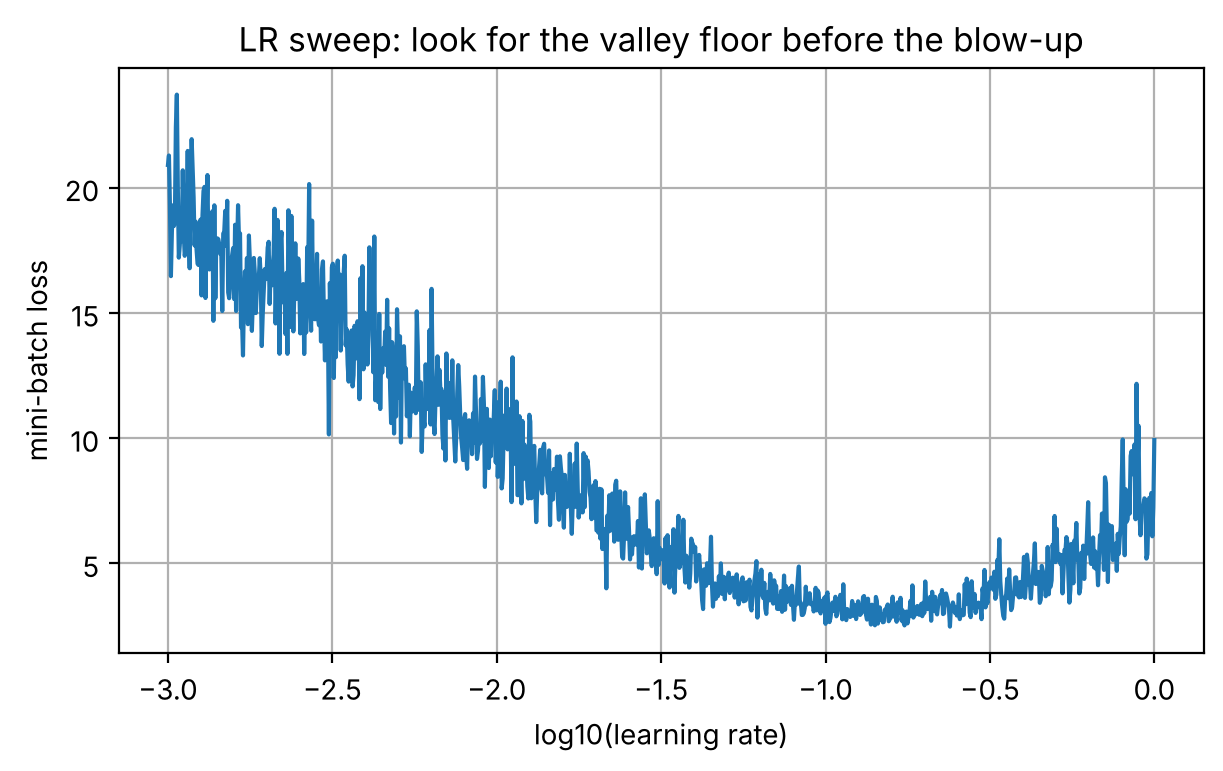

smoothed minimum near log10(lr) = -0.81  ->  lr ~ 0.155


In [23]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10 ** lre

ps = init_params()
lri, lossi = [], []
torch.manual_seed(1)
for i in range(1000):
    ix = torch.randint(0, Xtr.shape[0], (32,))
    loss = F.cross_entropy(forward(ps, Xtr[ix]), Ytr[ix])
    for p in ps: p.grad = None
    loss.backward()
    lr = lrs[i]
    with torch.no_grad():
        for p in ps:
            p -= lr * p.grad        # FIXED: (1) minus sign  (2) actually USES lr, not a hard-coded 0.1
    lri.append(lre[i].item()); lossi.append(loss.item())

plt.figure(figsize=(7, 3.8)); plt.plot(lri, lossi)
plt.xlabel("log10(learning rate)"); plt.ylabel("mini-batch loss"); plt.title("LR sweep: look for the valley floor before the blow-up")
plt.show()
best = min(range(1000), key=lambda i: sum(lossi[max(0, i-10):i+10]) / len(lossi[max(0, i-10):i+10]))
print(f"smoothed minimum near log10(lr) = {lri[best]:.2f}  ->  lr ~ {10**lri[best]:.3f}")

> **Bug box (your cell 73):** you computed `lr = lrs[i]` and then updated with a hard-coded `0.1 * p.grad`. So your sweep never used the swept rate; its plot (loss up to 11,468 vs `lri`) is the ascent bug plotted against a variable that did nothing. Two fixes: `-=`, and actually multiply by `lr`.

> **Self-test:** The sweep's loss is noisy. Name two reasons.
<details><summary>Answer</summary>
(1) Each point is a loss on a different random mini-batch of 32. (2) The weights are changing while the learning rate changes, so you never measure the same model twice. Use the sweep to find the *order of magnitude*, not an exact value.
</details>

---
## 12. Putting it together: train, evaluate, compare model sizes

### ELI5
Run the loop (pick 32 -> predict -> measure surprise -> blame -> small step) many times. Take big strides first, then **shrink the stride** (learning-rate decay) to settle into the valley, like first running toward a house and then walking carefully to the door.

### Math
Loop: sample batch -> $\mathcal{L}$ -> $\nabla\mathcal{L}$ -> $\theta\leftarrow\theta-\eta\nabla\mathcal{L}$.
Parameters for embedding dim $d$ and hidden width $H$: $\;27d+(3d)H+H+27H+27$.
- $d=2,H=100$: $54+600+100+2700+27=3481$.
- $d=10,H=200$: $270+6000+200+5400+27=11{,}897$.

In [23]:
@torch.no_grad()
def split_loss(ps, Xd, Yd):
    return F.cross_entropy(forward(ps, Xd), Yd).item()

def train(emb_dim=2, hidden=100, steps=30000, lr_hi=0.1, lr_lo=0.01, decay_at=0.8, batch=32, seed=2147483647):
    ps = init_params(emb_dim, hidden, seed)
    gen = torch.Generator().manual_seed(seed + 1)
    curve = []
    for i in range(steps):
        ix = torch.randint(0, Xtr.shape[0], (batch,), generator=gen)
        loss = F.cross_entropy(forward(ps, Xtr[ix]), Ytr[ix])
        for p in ps: p.grad = None
        loss.backward()
        lr = lr_hi if i < decay_at * steps else lr_lo
        with torch.no_grad():
            for p in ps: p -= lr * p.grad
        curve.append(loss.item())
    return ps, curve

import time
results = {}
for name, (d, H) in {"small (d=2,H=100)": (2, 100), "bigger (d=10,H=200)": (10, 200)}.items():
    t0 = time.time()
    ps_, curve = train(d, H)
    results[name] = (ps_, curve)
    n_par = sum(p.numel() for p in ps_)
    print(f"{name:22s} params={n_par:6d}  train={split_loss(ps_, Xtr, Ytr):.4f}  dev={split_loss(ps_, Xdev, Ydev):.4f}  ({time.time()-t0:.0f}s)")
print(f"\nreference points:  uniform guess = {math.log(27):.3f}")

small (d=2,H=100)      params=  3481  train=2.3568  dev=2.3594  (38s)
bigger (d=10,H=200)    params= 11897  train=2.2368  dev=2.2565  (57s)

reference points:  uniform guess = 3.296


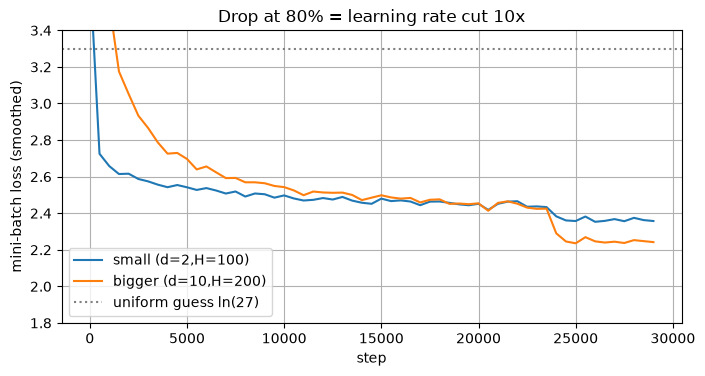

In [24]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for name, (_, curve) in results.items():
    k = 500
    sm = [sum(curve[i:i+k]) / k for i in range(0, len(curve) - k, k)]
    ax.plot(range(0, len(curve) - k, k), sm, label=name)
ax.axhline(math.log(27), color="gray", ls=":", label="uniform guess ln(27)")
ax.set_xlabel("step"); ax.set_ylabel("mini-batch loss (smoothed)"); ax.set_ylim(1.8, 3.4); ax.legend()
ax.set_title("Drop at 80% = learning rate cut 10x"); plt.show()

**How to read the table above:**
- train $\approx$ dev for both -> not overfitting yet; the models are **underfitting / under-trained**, so a bigger model or more steps still helps.
- If train were far below dev, you'd be memorising -> shrink the model, add data, or stop earlier.
- Your cell 76 ("we can increase the neural net in w1 and 22") is this experiment: more capacity in `W1`/`C`. Verify it with numbers, not hope: the table is the verification.

> **Bug box (your cell 76):** that is prose inside a *code* cell -> `SyntaxError` if run. Put notes in a markdown cell.

> **Self-test:** The bigger model gets a lower *dev* loss. Does that prove "bigger is better"? What else should you check before saying that?
<details><summary>Answer</summary>
No. Check (1) it wasn't just one lucky seed (repeat with a different seed), (2) that the gap train vs dev isn't opening up, (3) compute/time cost, (4) that you tuned the learning rate for *both*, since the best lr can differ with size.
</details>

---
## 13. Looking inside: the learned embedding map

### ELI5
At the start the 27 ID cards are random addresses, so the map is a meaningless scatter. After training, the network has *moved* letters around so that letters used in similar ways sit close together. Plot the 2D model's `C` before vs after.

### Math
Each character is a point $C[i]\in\mathbb{R}^2$. Distance in this space is meaningful only because the loss pulled interchangeable letters together (they need similar downstream behaviour).

**3B1B:** directions/clusters in embedding space encode meaning: **GPT @ 12:27** ([link](https://www.youtube.com/watch?v=wjZofJX0v4M&t=747s)).

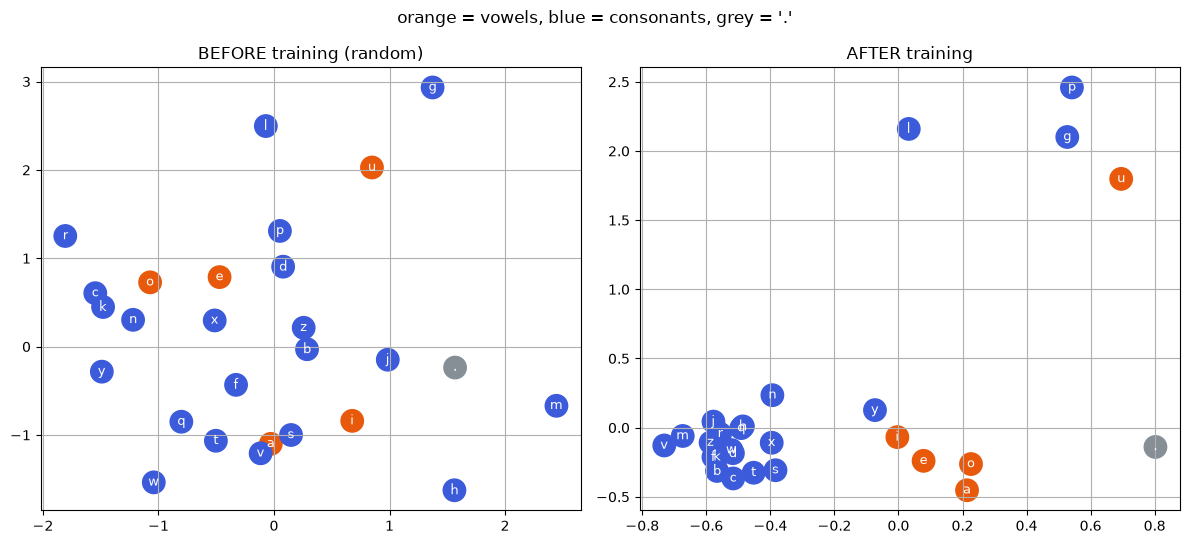

In [25]:
C_before = init_params(2, 100)[0].detach()
C_after = results["small (d=2,H=100)"][0][0].detach()

fig, axs = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, Cm, title in [(axs[0], C_before, "BEFORE training (random)"), (axs[1], C_after, "AFTER training")]:
    ax.scatter(Cm[:, 0], Cm[:, 1], s=260, c=["#e8590c" if itos[i] in "aeiou" else ("#868e96" if itos[i] == "." else "#3b5bdb") for i in range(V)])
    for i in range(V):
        ax.text(Cm[i, 0].item(), Cm[i, 1].item(), itos[i], ha="center", va="center", color="white", fontsize=9)
    ax.set_title(title)
plt.suptitle("orange = vowels, blue = consonants, grey = '.'", y=0.98)
plt.tight_layout(); plt.show()

> **Bug box (your cell 77):** you plotted `C` *after* the ascent runs had mutated it in place (`p.data +=` changes the same tensor), or before any real training. Either way the picture is noise. The plot only means something after a **correct** training run, like the right-hand panel here.
> **Honest caveat:** with only 2 dimensions the clusters are rough. The model is free to use the extra capacity of `W1` to separate letters, so don't over-read the map.

> **Self-test:** Why can't a vowel cluster appear unless training pushes it there?
<details><summary>Answer</summary>
The loss never sees the map. Gradients move each card only if moving it reduces surprise. Vowels cluster because they are interchangeable in many contexts, so giving them similar addresses is a cheap way to lower the loss.
</details>

---
## 14. Using the model: generating names

### ELI5
A model that gives "% for the next letter" can *write*: start with `...`, roll a weighted die using the percentages, append the letter, slide the peephole, repeat until it rolls `.`. High temperature = wilder dice, low = safer.

### Math
$$y_t\sim\text{Categorical}\big(p(\cdot\mid y_{t-3:t-1})\big),\qquad p(T)=\operatorname{softmax}(z/T)$$

**3B1B:** "predict, sample, repeat": **GPT @ 0:00** ([link](https://www.youtube.com/watch?v=wjZofJX0v4M)), and temperature at 22:22 ([link](https://www.youtube.com/watch?v=wjZofJX0v4M&t=1342s)). A GPT does the same loop; only the network in the middle is different.

In [26]:
@torch.no_grad()
def sample_names(ps, n=10, T=1.0, seed=2147483647 + 10):
    gen = torch.Generator().manual_seed(seed)
    out = []
    for _ in range(n):
        ctx, name = [0] * block_size, []
        while len(name) < 25:
            logits = forward(ps, torch.tensor([ctx]))[0] / T
            ix = torch.multinomial(F.softmax(logits, 0), 1, generator=gen).item()
            if ix == 0: break
            name.append(itos[ix]); ctx = ctx[1:] + [ix]
        out.append("".join(name))
    return out

best_ps = results["bigger (d=10,H=200)"][0]
for T in [0.5, 1.0, 2.0]:
    print(f"T={T}:", sample_names(best_ps, 8, T))
print("untrained model:", sample_names(init_params(10, 200), 5))

T=0.5: ['carleigh', 'brie', 'kharilli', 'taylee', 'andelle', 'ahmer', 'ameryn', 'alayni']
T=1.0: ['carpavelle', 'harith', 'mrighte', 'caspley', 'kena', 'hute', 'amerynci', 'aqei']
T=2.0: ['carpahxque', 'hlvi', 'kimli', 'rehty', 'hacadske', 'rahnen', 'dperric', 'kaquiu']
untrained model: ['khckyfkjryhcyryhcyyshvyyh', 'kkfkkrnnxvymhjzigkyojvyhc', 'khfckyfcuyhouyhouyhouyhod', 'khfckyfkjryhcyysewgthxjyr', 'kkhgkbdnrzoahxjyrnuhddrew']


---
## 15. Cheat-sheet

### Shapes through the pipeline (`N` examples, `d` emb dim, `H` hidden)
| Step | Code | Shape | Math |
|---|---|---|---|
| input | `X` | `(N,3)` int | context ids |
| lookup | `C[X]` | `(N,3,d)` | $C[i]=\mathbf e_i^\top C$ |
| flatten | `.view(-1, 3*d)` | `(N,3d)` | relabel only |
| hidden | `tanh(x@W1+b1)` | `(N,H)` | $\tanh(xW_1+b_1)$ |
| logits | `h@W2+b2` | `(N,27)` | $z=hW_2+b_2$ |
| probs | `softmax(z,1)` | `(N,27)` | $e^{z_j}/\sum_k e^{z_k}$ |
| loss | `F.cross_entropy(z,Y)` | scalar | $-\frac1N\sum\log p_{n,y_n}$ |
| update | `p -= lr*p.grad` | per-param | $\theta\leftarrow\theta-\eta\nabla\mathcal L$ |

### Numbers worth remembering
- Uniform-guess loss = $\ln 27=3.296$. Healthy init loss $\approx$ this. Yours was 17.77 -> bad init.
- float32 `exp` overflows at $z\approx88.7$.
- Tiny-set floor (5 names): $5\ln5/32=0.2515$.
- Parameters: $27d+3dH+H+27H+27$ (3,481 for $d=2,H=100$).

### Every bug found in your notebook (all with evidence)
| # | Where | Bug | Evidence / fix |
|---|---|---|---|
| 1 | cell 3 | `x.append`, `y.append` lowercase | `NameError`; use `X`, `Y` |
| 2 | cell 23 | `emb @ w1 + b` | shape mismatch `(32,3,2)@(6,100)`; `b` undefined; use `emb.view(-1,6)@w1+b1` |
| 3 | cells 68, 72, 73 | `p.data += 0.1*p.grad` | **gradient ascent.** Your loss: 17.8 -> 88.0 -> 203.6 -> 11,468.7. Use `p -= lr*p.grad` |
| 4 | cell 73 | `lr = lrs[i]` computed but `0.1` used | sweep never swept; use `lr` |
| 5 | cells 72-73 | `randint(0, 32, (32,))` on a 32-row set | not a real mini-batch; sample from `Xtr` |
| 6 | cell 76 | prose in a code cell | `SyntaxError`; use markdown |
| 7 | cell 77 | embedding plotted from corrupted/untrained `C` | plot after a *correct* run |
| 8 | cell 32 | `a.storage()` | deprecated; `untyped_storage()` |
| 9 | cell 45 | comment says `(1,1000)` | bias is `(100,)` -> broadcast as `(1,100)` |
| 10 | cell 75 | `random.shuffle(words)` mutates the global list | shuffle a copy |

### Final exam: answer without scrolling up
1. What is the loss of a model that is perfectly uncertain over 27 characters?
2. Why is `-log p` the right "surprise" and not `1-p`?
3. What does `torch.cat` do that `.view` doesn't?
4. Why is the gradient of softmax+cross-entropy w.r.t. the logits just $(p-y)/N$?
5. Your loss goes *up* every step. Name your first suspect.
6. What breaks if you test on the same data you tuned on?

<details><summary>Answers</summary>

1. $\ln27\approx3.296$.
2. $-\log p$ is $0$ at $p=1$ and $\infty$ at $p=0$ (unbounded punishment for confident wrong answers), and it **adds** across independent events ($-\log(ab)=-\log a-\log b$). $1-p$ caps at 1 and gives weak gradients when you are badly wrong.
3. `cat` allocates new memory and copies; `.view` only changes the shape metadata on the same memory.
4. The chain rule through the $\log$ and the softmax's $e^{z_j}/\sum e^{z_k}$ cancels to $p_j-\mathbb 1[j=y]$ (verified numerically in section 8).
5. The sign of the update (are you doing `+=` instead of `-=`?), then the learning rate being too high.
6. The number becomes optimistic, because your choices adapted to that data. It no longer estimates performance on unseen data.
</details>